### The problem and approach

Given images of fried potatoes on a fixed plate. 
- Task 1: Segmentation and annotation for `light` and `orange`.
- Task 2: Detection and instance segmentation, applied on `light_hard` and `orage_hard`.
- Task 3: Relative depth estimation. 
- Task 4: Defect detection, applied on `light_defect`, `orange_defect`, `light_defect_hard`, `orage_defect_hard`
- Task 5: Use docker to wrap an inference application for Task 2, 3 and 4 . 

##### Summary of approach
- For Task 1, as the background and foreground are quite separable, let's address it by simple thresholding instead of using a complicated  segmentation model.
- Attempted to solve Task 2 and Task 4 together by training one model that aims to detect 4 kinds of fried potatoes. 
- Task 3 is solved by using a monocular depth estimation model. The model predicts global depth, from which local depths (i.e., of individual instances) are derived.  

The detail of each task is described in next sections. 

##### Instance segmentation approach 
- The segmentation is done by Otsu thresholding method directly on original image for non-defect cases. For defect cases, as foregrounds contain multiple colors, it is better to substract the background before thresholding. 
- Find connected components and annotate them as separated instances (i.e., patches). 

##### Data strategy
- There are options to use original images for model training. However, original images are much simpler than actual cases (`*hard` folders). I think a model trained on images like original ones won't perform well for `hard` cases. In other words, a data synthesizer to generate more data with higher degree of complication is neccessary. 
- After segmentation, we can further improve the annotation by manual approach. I prefer using this method in an actual project to ensure highest quality. 
- In this assignment, instead of manual modification, I will try filtering incorrect patches based on its area. Patches whose area are not falling in between 10% and 80% of all patches are considered as incorrect. 
- From correct patches, let's generate synthetic images. Here are detail of image synthesizer I implemented: 
    - Numbers of patches on each image a normal distribution, controllable by `patches_mean` and `patches_std` in `config.py`.  
    - Distances of patches to image center follow a normal distribution, as all images in `hard` directory has high density of potatoes around the center. I assume this is the general scenario. 
    - The randomization can be adjusted in accordance to any other requirements. 
    - Random rotation of patches 
    - Complication handling: 
        - Occlusion 
        - Depth mask, used for Task 3
- I prepared 10000 images, 90% are used for training and 10% for validation. 

##### Models
- For object detection and instance segmentation, I used Yolov8 
- For depth estimation, I used Unet with Densenet169 backbone (reference https://arxiv.org/pdf/2212.11363.pdf)
- Both models are trained only using synthetic images.

##### Inference 
- I made a simple demo with streamlit and containerzied in Docker as requested.  


##### Now, let's move to each processing step.
- Please use `requirements.txt` to create a ready environment. 
- This notebook was tested on: 
    - Ubuntu 20.04 
    - GPU: 1x Tesla T4 16GB 
    - Nvidia driver 450.142.00 


For illustration purpose, some cells' output were cleared.

### Segmentation and annotation

In [ ]:
#Load neccesary modules and file listing 
from data import *
from config import *
import matplotlib.pyplot as plt 

input_dir = f'{data_dir}/fried_potato' 

def show(imgs, title=None): 
    '''
        Display images horizontally 
    '''
    fig, axs = plt.subplots(1, len(imgs), figsize=(6 * len(imgs), 6))
    for ax, img in zip(axs, imgs):
        ax.imshow(img)
    axs[0].title.set_text(title)
    plt.show()
    
    
np.random.seed(5)
background_files = sorted(glob(f'{input_dir}/background/*.png'))
files = sum([glob(f'{input_dir}/{x}/*.png') for x in classes], [])
demo_files = sorted(np.random.choice(files, 9, replace=False)) #select 9 files for this report 
images = [cv2.imread(x) for x in demo_files]
backgrounds = [cv2.imread(x) for x in background_files]

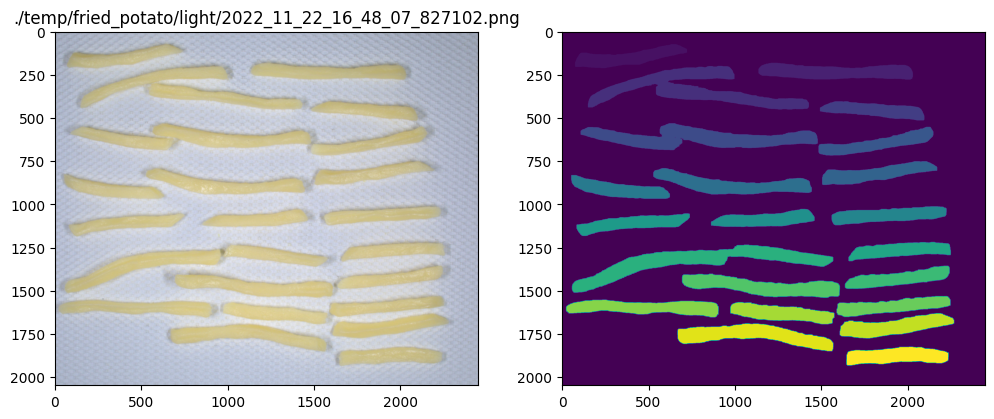

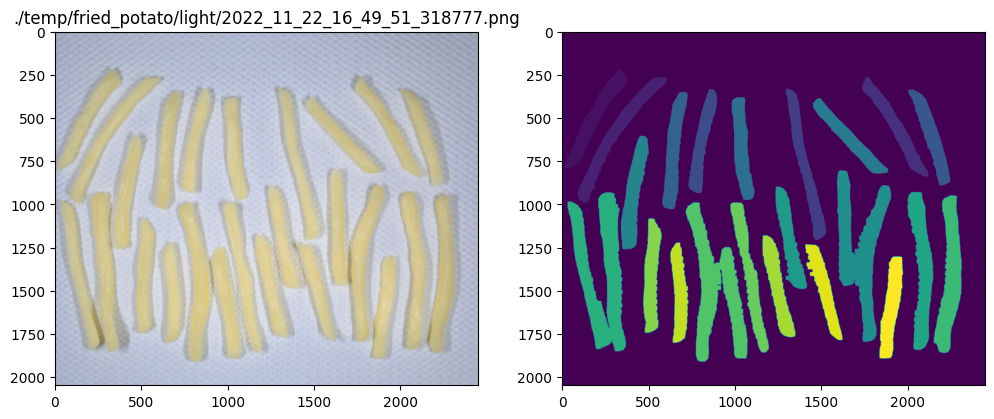

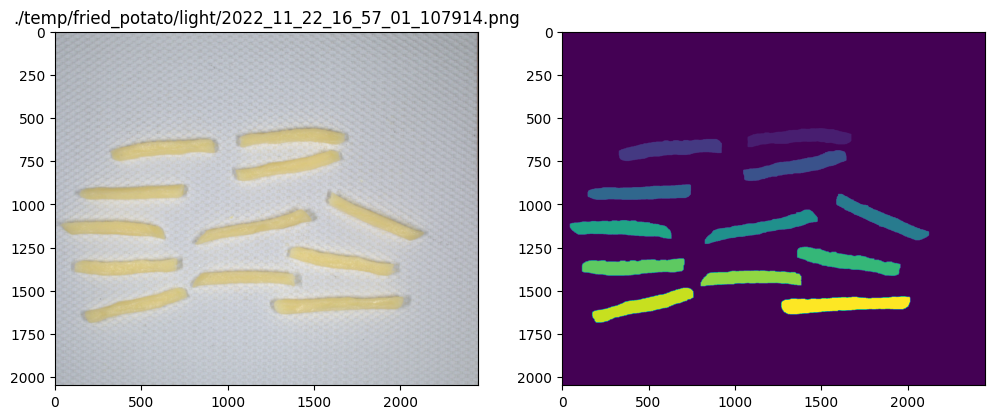

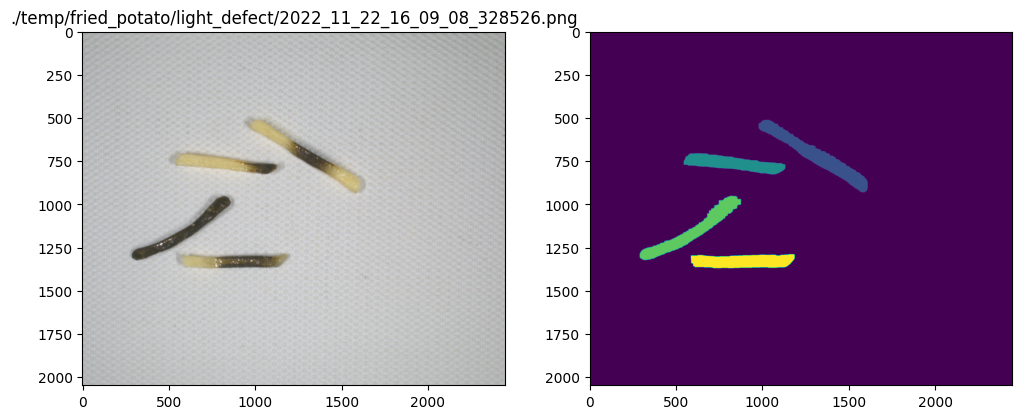

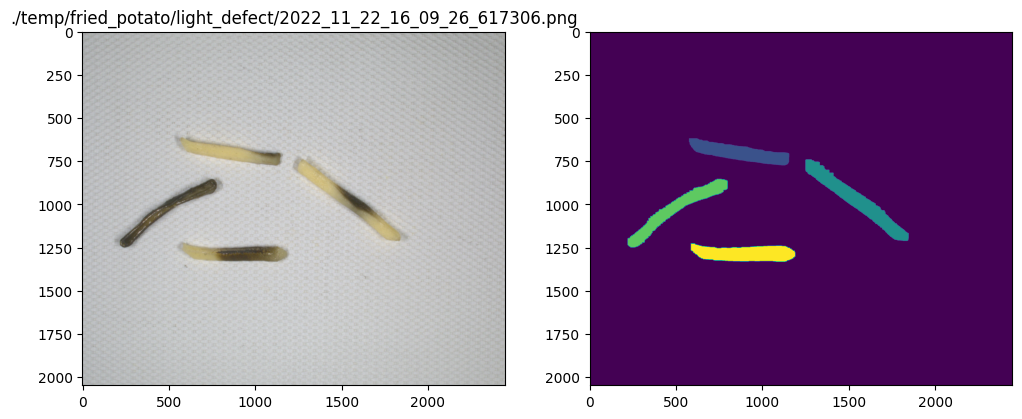

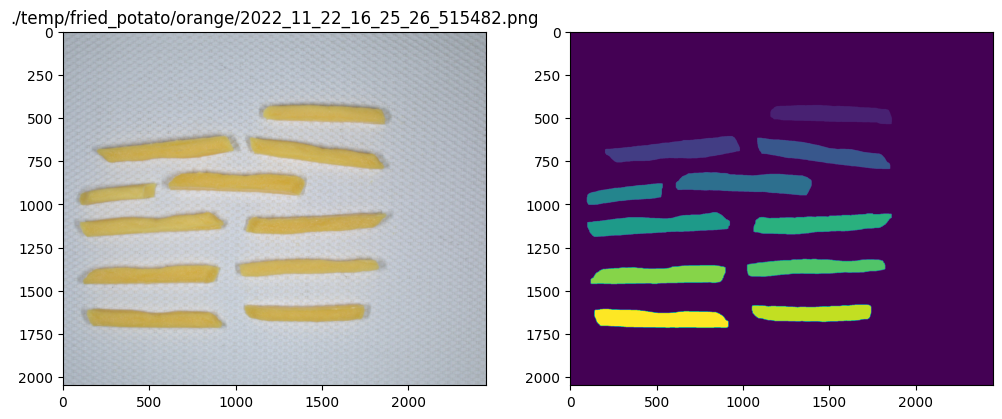

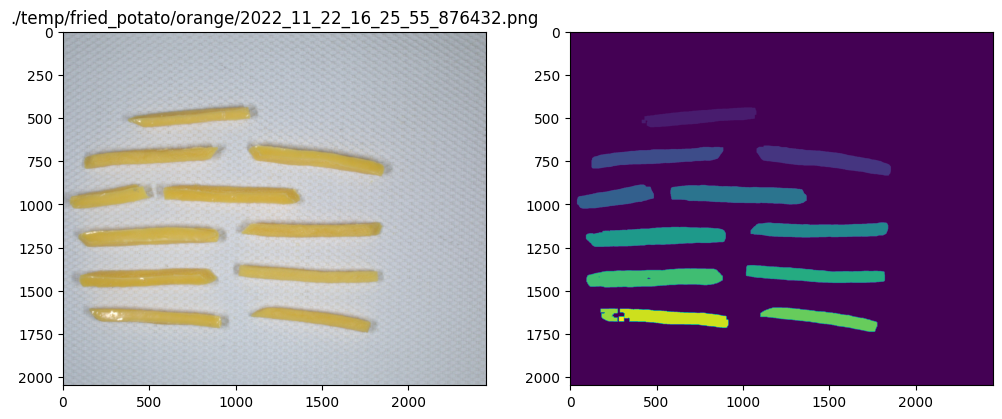

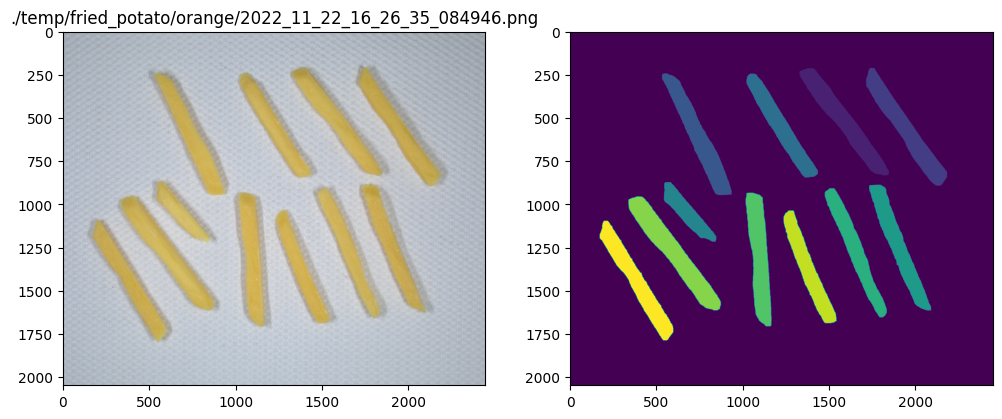

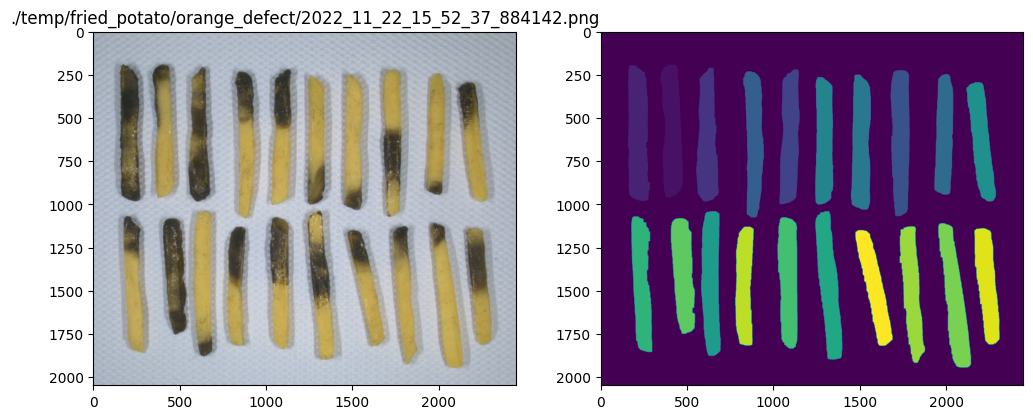

In [6]:
#Segmentation 
for image, name in zip(images, demo_files):
    mask = segmentation(image, backgrounds[0] if 'defect' in name else None)[1]
    show((image[:,:,::-1], mask), name)

In above results, there are cases that different objects are merged due to segmentation errors. Those merged patches will be filtered out based on area size. 

### Example of data synthesis

In [9]:
#Get all patches from available images 
from collections import Counter
patches, backgrounds = get_patches_from_files(files, background_files)
print(Counter((x['label'] for y in patches for x in y)))

extracting patches: 100%|██████████| 32/32 [00:20<00:00,  1.58it/s]

Counter({'light': 172, 'orange': 94, 'light_defect': 51, 'orange_defect': 35})


The filter was effective to remove merged patches. After running above next cell, you can check `patches` directory for image of extracted patches.
Next are examples of synthesis images.

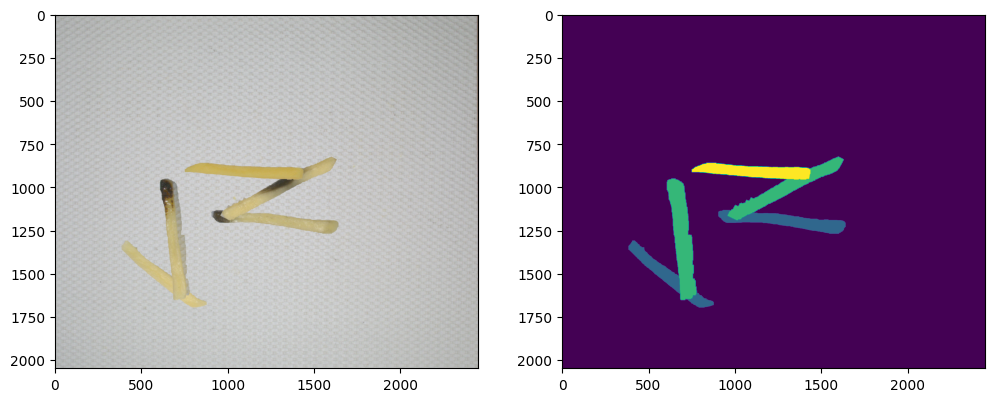

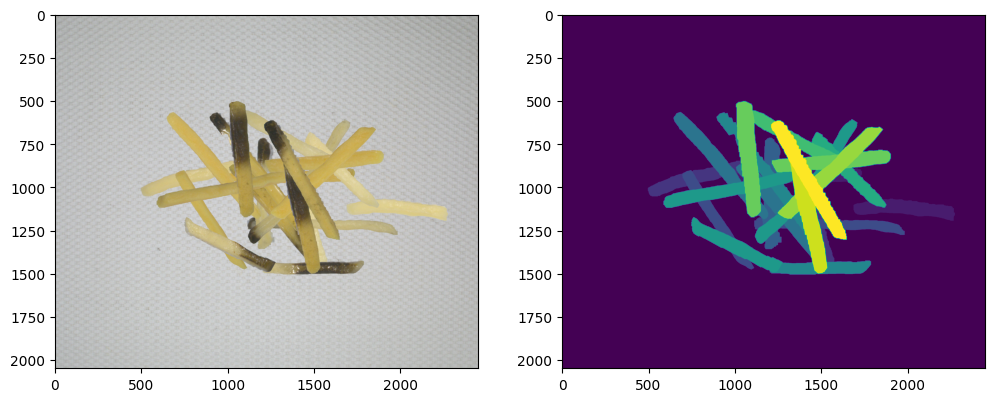

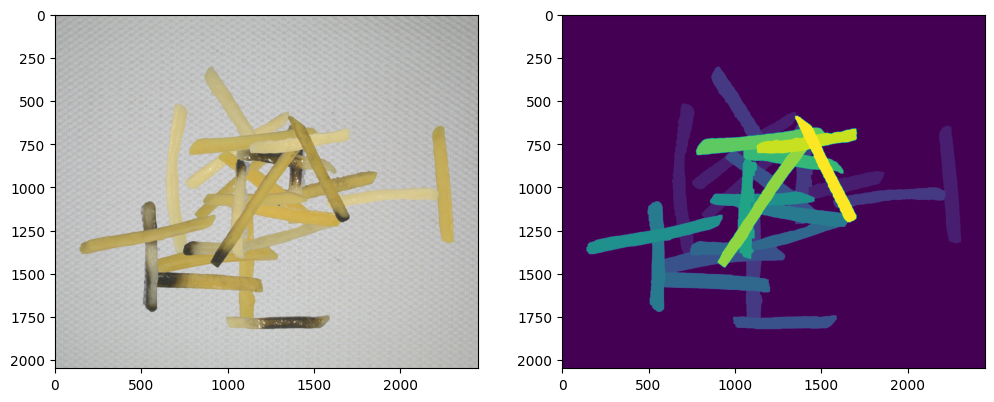

In [11]:
#Display generated image and depth mask 
#Same color --> same depth level. More yellow, nearer to camera. 
for pm in [5, 15, 30]: 
    image, instances, depth_mask = create_image(patches, backgrounds, patches_mean=pm, patches_std=5) 
    show((image[:,:,::-1], depth_mask))

In [ ]:
#Data generation, for training and validation 
#This function took about 30 minutes (with 16 parallel processes) to generate 10000 images, about 60GB hard disk is required. 
generate_data() 

### Model training

In [ ]:
#Detection & segmentation model training 
#Training process took about 3 hours on 1xT4 GPU
from ultralytics import YOLO
from config import *
model = YOLO("yolov8m-seg.pt") 
model.train(data=f'{data_dir}/dataset.yaml', **yolo_params) 
model.val()

#Below are metrics of: input training data, PR curve, and confusion matrix on validation set

<img src="docs/segment/train/labels.jpg" alt="Train labels" width="1000"/><br>
<img src="docs/segment/train/results.png" alt="Training curve" width="1000"/><br>
<img src="docs/segment/val/MaskPR_curve.png" alt="Val PR" width="500"/>
<img src="docs/segment/val/confusion_matrix_normalized.png" alt="Val confusion matrix" width="500"/><br>
<img src="docs/segment/val/val_batch0_labels.jpg" alt="Val label" width="500"/>
<img src="docs/segment/val/val_batch0_pred.jpg" alt="Val pred" width="500"/>


- In general, the result indicates an acceptable performance on differentiating classes of objects. However, there is a considerable confusion betweeen foreground and background. 
- As visualized above, some occluded potatoes are difficult to recognize. 
  - I would improve this issue using a 2-steps detection model (i.e., with FPN) for a better accuracy. 
  - Depending on use cases, if potatoes of top layers are picked first, it is easier to detect such those potatoes using just the current model with a little modification on training data (e.g., labelled lower layers as background) or combine with depth estimation module. 




In [ ]:
#Depth estimation model training 
#Training process took about 5 hours on 1xT4 GPU
from mono import MONO 
from config import *
model = MONO()
model.train([f'{data_dir}/depth_train.txt', f'{data_dir}/depth_val.txt'], **mono_params)

#Below are metrics during training 

<img src="docs/depth/metric1.png" alt="" width="500">
<img src="docs/depth/metric2.png" alt="" width="500"/><br>

### Prediction examples
Let's wrap two models in a class named ModelComplex and test models on given data 
- Because my GPU is enough for just one model, I use CPU for YOLO (still quite fast) and GPU for MONO. 

In [ ]:
from model_complex import ModelComplex
models = ModelComplex('runs/segment/train/weights/best.pt', 'runs/depth/cp.ckpt') 

In [ ]:
from PIL import Image 

files = sorted(glob(f'{data_dir}/fried_potato/*/*.png'))
files = [x for x in files if any(y in x for y in classes)]
images = [Image.open(x) for x in files]
results = models(images)
for file, image, result in zip(files, images, results):
    show([image, *result], file)

- As more visualization for detection problems, the detection model may confuse due to objects shadows. Shadows are sometimes recognized as potatoes and especially as `defect` because of dark color but similar shape. This could be resovled by muticulous annotation to remove shadow from objects or label also the shadow as a separated class if the model still gets confusion. 
- There are cases where a potato is almost completely black. In this case, it is detected as `defect` regardless of `light` or `orange`. 
- The depth estimation model is greatly affected by the centralization of objects. As shown on 3rd columns of above images,  nearer distance (i.e., brighter color) is detected in center of image regardless the distribution of objects. However, the localization using segmentation result and depth mask can solve the problem and assign more accurate relative depths, as shown on 4th column. Objects with same depth are in same color, object with nearer distance to camera are brighter. 
  

### Demo application 

In [ ]:
%%bash 
mkdir weights
cp runs/segment/train/weights/best.pt weights/yolo.pt 
cp runs/depth/cp.ckpt.* weights/
streamlit run app.py --server.port 5555

Screenshot of the demo application

<img src="docs/app/Screenshot1.png" alt="" width="600"/><br>
<img src="docs/app/Screenshot2.png" alt="" width="600"/><br>
<img src="docs/app/Screenshot3.png" alt="" width="600"/><br>

### Docker container
- Let's wrap above demo application in a docker image and run it. 
- On a machine without GPU, CPU will be used automatically. I also tested the Dockerfile on a normal Macbook

In [ ]:
%%bash 
docker build -t khai/demo . 
docker run -p 5555:5555 --gpus all khai/demo:latest 

In [5]:
#HTML version of this report
!jupyter nbconvert --to html README.ipynb

[NbConvertApp] Converting notebook README.ipynb to html
[NbConvertApp] Writing 54120087 bytes to README.html
